# HW2 - Logistic Regression

Use **scikit-learn** to train and evaluate a three-class classifier, and **SciPy** to connect its probability output to softmax. Question 6 is worth **20 points**, divided into 3 + 7 + 6 + 4.

Read each short example, complete the next exercise, and inspect its output before continuing. There are **12 expressions to fill in** across four exercise cells. Replace each `...` and remove that cell's `raise NotImplementedError(...)` line when it is complete. Keep the supplied data splits and model settings.

**Answer Language:** All answers must be written in English, including the written explanations in this notebook.

Submit the completed notebook as a PDF with its outputs, two figures and the short written answers. Restart the kernel and run all cells in order before exporting.

## Environment

Use a Python 3.12 environment for the tested setup. The reference was run with NumPy 2.2.6, SciPy 1.15.3, scikit-learn 1.7.2 and Matplotlib 3.10.7. The dataset is included in scikit-learn.

If you need to install these versions, run the following in a new notebook cell, then restart the kernel and run the imports below.

```python
%pip install numpy==2.2.6 scipy==1.15.3 scikit-learn==1.7.2 matplotlib==3.10.7
```

In [1]:
%matplotlib inline
import numpy as np
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, ConfusionMatrixDisplay

print("Versions", np.__version__, scipy.__version__, sklearn.__version__)

Versions 2.2.6 1.15.3 1.7.2


## Load data and keep three separate splits

`load_wine()` provides 178 observations, 13 chemical measurements per observation, and labels 0, 1 and 2. Each row of `X` is one observation, and each column is a feature.

Run the supplied calls to `train_test_split`. The first reserves 20% for testing. The second reserves 25% of the remaining observations for validation. `stratify` keeps class proportions similar, and `random_state` makes the split reproducible. Use training rows to fit models, validation rows to choose a setting, and test rows for the final evaluation.

Question 4 names its three classes 1, 2 and 3; the Wine labels used here are 0, 1 and 2.

In [2]:
wine = load_wine()
X, y = wine.data, wine.target
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.2, random_state=182, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=182, stratify=y_dev)
print("Training", X_train.shape, "validation", X_val.shape, "test", X_test.shape)
print("Class labels", np.unique(y), "class names", wine.target_names)

Training (106, 13) validation (36, 13) test (36, 13)
Class labels [0 1 2] class names ['class_0' 'class_1' 'class_2']


## 6.1 Fit and reuse a StandardScaler - 3 points

`StandardScaler` learns a mean and standard deviation for each feature. `fit_transform(X)` learns them and transforms `X`. `transform(X_new)` reuses the learned values on another input matrix. The following small example demonstrates both calls.

In [3]:
toy_scaler = StandardScaler()
print(toy_scaler.fit_transform([[1., 10.], [3., 30.]]))
print(toy_scaler.transform([[2., 20.]]))

[[-1. -1.]
 [ 1.  1.]]
[[0. 0.]]


In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit and transform the training inputs.
X_val_scaled = scaler.transform(X_val)    # Transform validation inputs with the fitted scaler.
print("Training means", X_train_scaled.mean(axis=0).round(6))
print("Training standard deviations", X_train_scaled.std(axis=0).round(6))

Training means [ 0. -0.  0.  0. -0. -0.  0. -0. -0. -0.  0. -0.  0.]
Training standard deviations [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


**Short answer A.** Why do we use `transform` on validation inputs? Answer in one or two sentences.

We use transform to apply the means and standard deviations learned from the training inputs to the validation inputs. Fitting the scaler on validation inputs would use validation information during preprocessing and change the scaling used by the trained model.

## 6.2 Fit a classifier and inspect probabilities - 7 points

A `Pipeline` joins preprocessing and a classifier. The worked example below combines `StandardScaler()` and `LogisticRegression()`. Calling `fit` on the pipeline fits both steps on the training inputs. Calling `predict` or `predict_proba` reuses the fitted preprocessing.

Pass the **raw** `X_train`, `X_val` and `X_test` to every pipeline call below. Its internal scaler performs the transformation. `C` controls the inverse regularization strength, `solver="lbfgs"` selects the library's optimization routine, and `max_iter` sets its iteration limit.

In [5]:
demo_model = make_pipeline(
    StandardScaler(), LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000))
demo_model.fit(X_train, y_train)
print("First two predictions", demo_model.predict(X_val[:2]))

First two predictions [1 2]


Complete the next cell using these calls.

| API | Meaning |
| --- | --- |
| `model.predict(X)` | Return one class label per input row. |
| `model.predict_proba(X)` | Return a probability matrix whose columns follow `model.classes_`. |
| `accuracy_score(y_true, y_pred)` | Return the fraction of correctly predicted labels. |
| `log_loss(y_true, probabilities, labels=model.classes_)` | Return mean cross-entropy, using natural logarithms. |

`decision_function(X)` returns the three class scores for each row. Use `scipy.special.softmax` to turn these scores into probabilities, connecting to Question 4. Choose the axis that normalizes **over the three classes within each input row**. The supplied comparison checks the result against `predict_proba`.

In [6]:
val_pred = demo_model.predict(X_val)
val_proba = demo_model.predict_proba(X_val)
val_accuracy = accuracy_score(y_val, val_pred)
val_ce = log_loss(y_val, val_proba, labels=demo_model.classes_)
from_scores = softmax(demo_model.decision_function(X_val), axis=1)
print("Label shape", val_pred.shape, "probability shape", val_proba.shape)
print("Probability columns", demo_model.classes_)
print("First three probability rows", val_proba[:3].round(4))
print("First three row sums", val_proba[:3].sum(axis=1))
print("Validation accuracy", val_accuracy, "cross-entropy", val_ce)
np.testing.assert_allclose(from_scores, val_proba, atol=1e-12)

Label shape (36,) probability shape (36, 3)
Probability columns [0 1 2]
First three probability rows [[4.710e-02 9.519e-01 9.000e-04]
 [6.500e-03 3.100e-02 9.624e-01]
 [2.930e-02 2.990e-02 9.407e-01]]
First three row sums [1. 1. 1.]
Validation accuracy 1.0 cross-entropy 0.06044653483137801


**Short answer B.** State the two output shapes, explain what each probability column represents, and explain your `softmax` axis choice. Answer in two or three sentences.

The predicted-label array has shape (36,), and the probability matrix has shape (36, 3). Its columns give the probabilities of classes 0, 1 and 2, respectively, following demo_model.classes_. Using axis=1 normalizes across the three class scores within each observation, so each row sums to one.

## 6.3 Compare regularization settings - 6 points

Smaller `C` means stronger L2 regularization. Complete the **three calls inside the supplied loop** to fit each candidate on training inputs, obtain validation probabilities, and compute validation cross-entropy.

The code prints a comparison table and selects the candidate with the smallest validation cross-entropy. The sorted `C_values` and `np.argmin` choose the smallest `C` on an exact tie. The next supplied cell plots the validation losses. Keep the selected fitted object for the final evaluation.

In [7]:
C_values = [0.01, 0.1, 1.0, 10.0]
models, val_losses = [], []
print("C      validation accuracy   validation cross-entropy")
for C in C_values:
    candidate = make_pipeline(
        StandardScaler(), LogisticRegression(C=C, solver="lbfgs", max_iter=2000))
    candidate.fit(X_train, y_train)  # Fit candidate on the raw training inputs and training labels.
    candidate_proba = candidate.predict_proba(X_val)
    candidate_ce = log_loss(y_val, candidate_proba, labels=candidate.classes_)
    models.append(candidate)
    val_losses.append(candidate_ce)
    print(f"{C:5g}  {candidate.score(X_val, y_val):19.6f}   {candidate_ce:.6f}")
best_index = int(np.argmin(val_losses))
best_model = models[best_index]
print("Selected C", C_values[best_index])

C      validation accuracy   validation cross-entropy
 0.01             1.000000   0.466277
  0.1             1.000000   0.151081
    1             1.000000   0.060447
   10             1.000000   0.045481
Selected C 10.0


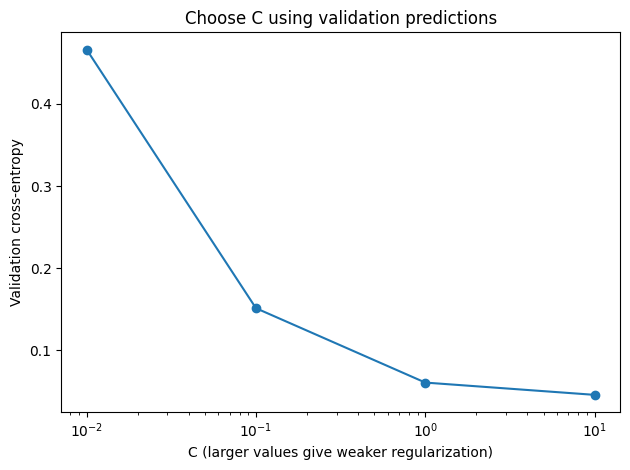

In [8]:
plt.semilogx(C_values, val_losses, marker="o")
plt.xlabel("C (larger values give weaker regularization)")
plt.ylabel("Validation cross-entropy")
plt.title("Choose C using validation predictions")
plt.tight_layout()
plt.show()

**Short answer C.** Which candidate has the strongest regularization, and which `C` was selected? Can validation accuracy distinguish the four candidates in your table? Explain what the cross-entropies tell you. Answer in two or three sentences.

The strongest regularization is C=0.01, and C=10 was selected because it has the lowest validation cross-entropy. Validation accuracy cannot distinguish the four candidates because all four achieve 1.0. The cross-entropies decrease from 0.466277 to 0.151081, 0.060447 and 0.045481 as C increases, showing that the probabilities assigned to the correct classes improve overall even though the predicted labels remain correct.

## 6.4 Evaluate the selected model - 4 points

Keep `best_model` fixed and complete the two prediction calls on `X_test`. The supplied metric calls report test accuracy and cross-entropy. `ConfusionMatrixDisplay.from_predictions` draws a confusion matrix, whose **rows are true classes** and **columns are predicted classes**. Diagonal entries count correct predictions. An entry in row 1 and column 2 counts true class-1 examples predicted as class 2.

Selected C 10.0 test accuracy 0.9722222222222222 test CE 0.05378990904598078


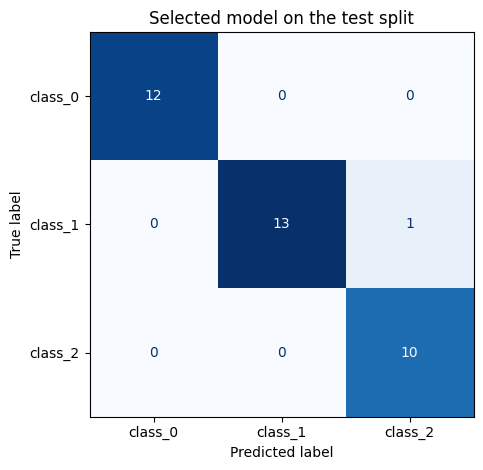

In [9]:
test_pred = best_model.predict(X_test)
test_proba = best_model.predict_proba(X_test)
test_accuracy = accuracy_score(y_test, test_pred)
test_ce = log_loss(y_test, test_proba, labels=best_model.classes_)
print("Selected C", C_values[best_index], "test accuracy", test_accuracy, "test CE", test_ce)
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=best_model.classes_, display_labels=wine.target_names,
    cmap="Blues", colorbar=False)
plt.title("Selected model on the test split")
plt.tight_layout()
plt.show()

**Short answer D.** Read the number of correct test predictions from the diagonal and describe any off-diagonal errors, or state that there are none. Why must you choose `C` before inspecting these test results? Answer in two or three sentences.

The diagonal contains 12, 13 and 10 correct predictions, for a total of 35 out of 36. The only off-diagonal error is one true class-1 observation predicted as class 2. We must choose C before inspecting the test results so the test set remains independent of model selection and provides an unbiased estimate of generalization performance.

## API references

The examples and API descriptions above contain the information needed for these exercises. For additional examples, consult the official documentation.

- [StandardScaler](https://scikit-learn.org/1.7/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Pipeline](https://scikit-learn.org/1.7/modules/generated/sklearn.pipeline.Pipeline.html)
- [LogisticRegression](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [Classification metrics](https://scikit-learn.org/1.7/modules/model_evaluation.html#classification-metrics)
- [SciPy softmax](https://docs.scipy.org/doc/scipy-1.15.3/reference/generated/scipy.special.softmax.html)